### **0. Environment Setup**

**How to use this template:** (1) in section 1 choose the **task** and **load your data**; (2) in section 2 **change the parameters** of the models; (3) run all the cells – the table in section 3 compares every model.

In [1]:
#Import Libs
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from sklearn.datasets import load_breast_cancer, load_diabetes, load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error,
                             silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore")                                                  # keeps the output clean (remove this line while debugging)
RED, DARK = "#CD2027", "#404040"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=[RED, DARK, "#E9A0A3", "#7F7F7F"])})

### **1. Data and Settings**

**This is the only cell where you load your data.** Choose the **task**:

| TASK | What it does | `TARGET` |
|---|---|---|
| `"classification"` | predicts a **category** | column with the classes |
| `"regression"` | predicts a **number** | column with the value |
| `"clustering"` | finds **groups** | optional: true groups, only to *compare* (`""` = none) |

Set `USE_DEMO = False` and `CSV_PATH` to use your own file. Text columns become dummies automatically.

In [ ]:
#Settings and Data ( the Only Cell to Edit to Load Your Data )
TASK = "classification"             # "classification" | "regression" | "clustering"
USE_DEMO = True                   # True: demo dataset of the task · False: reads your CSV file
CSV_PATH = "your_data.csv"        # path of your file
TARGET = "target"                 # target column (clustering: optional, "" = none)
TEST_SIZE, CV, N_CLUSTERS, SEED = 0.3, 5, 3, 42       # test share · cross-validation folds · number of clusters · random seed

df = ({"classification": load_breast_cancer, "regression": load_diabetes, "clustering": load_wine}[TASK](as_frame=True).frame if USE_DEMO else pd.read_csv(CSV_PATH)).dropna().reset_index(drop=True)
X = pd.get_dummies(df.drop(columns=[TARGET] if TARGET else []))                                       # features (text -> dummies)
y = pd.factorize(df[TARGET], sort=True)[0] if TASK == "classification" else (df[TARGET].to_numpy() if TARGET else None)
CLASSES = [str(c) for c in np.unique(df[TARGET])] if TASK == "classification" else None
print(f"{TASK}: {X.shape[0]} rows x {X.shape[1]} features | target: {TARGET or 'none'}", "| classes:" if CLASSES else "", CLASSES or "")

classification: 569 rows x 30 features | target: target | classes: ['0', '1']

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


### **2. Models and Parameters**

**Change the parameters here** and run again. The most useful ones:

| Model | Parameters to try |
|---|---|
| Decision tree · Random forest | `max_depth`, `min_samples_leaf`, `n_estimators`, `max_features` |
| Gradient boosting · AdaBoost | `n_estimators`, `learning_rate`, `max_depth` |
| SVM (RBF) | `C`, `gamma` |
| k-NN | `n_neighbors` |
| MLP | `hidden_layer_sizes`, `alpha` |
| Ridge · Lasso · Logistic | `alpha` / `C` (regularisation) |
| K-Means · Hierarchical · Spectral · GMM | `n_clusters` (`n_components`) |
| DBSCAN | `eps`, `min_samples` |

To remove a model, delete its line; to add one, copy a line. **DBSCAN is very sensitive to `eps`** (with many features try 2–3; too large gives a single cluster and the silhouette becomes `NaN`).

In [ ]:
#Models and Parameters ( Edit the Parameters; Features Are Standardised Automatically )
MODELS = {
    "classification": {
        "Logistic Regression": LogisticRegression(C=1.0, max_iter=5000),
        "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=SEED),
        "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=None, random_state=SEED),
        "Gradient Boosting":   GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, random_state=SEED),
        "AdaBoost":            AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=SEED),
        "k-NN":                KNeighborsClassifier(n_neighbors=5),
        "SVM (RBF)":           SVC(C=1.0, gamma="scale", probability=True, random_state=SEED),
        "Naive Bayes":         GaussianNB(),
        "MLP":                 MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-4, max_iter=2000, random_state=SEED)},
    "regression": {
        "Linear Regression":   LinearRegression(),
        "Ridge":               Ridge(alpha=1.0),
        "Lasso":               Lasso(alpha=0.1),
        "Decision Tree":       DecisionTreeRegressor(max_depth=5, random_state=SEED),
        "Random Forest":       RandomForestRegressor(n_estimators=200, max_depth=None, random_state=SEED),
        "Gradient Boosting":   GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, max_depth=3, random_state=SEED),
        "k-NN":                KNeighborsRegressor(n_neighbors=5),
        "SVR (RBF)":           SVR(C=100.0, gamma="scale"),
        "MLP":                 MLPRegressor(hidden_layer_sizes=(64,), alpha=1e-4, early_stopping=True, max_iter=3000, random_state=SEED)},
    "clustering": {
        "K-Means":             KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED),
        "Hierarchical (Ward)": AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward"),
        "DBSCAN":              DBSCAN(eps=2.4, min_samples=5),
        "GMM":                 GaussianMixture(n_components=N_CLUSTERS, covariance_type="full", random_state=SEED),
        "Spectral":            SpectralClustering(n_clusters=N_CLUSTERS, affinity="nearest_neighbors", random_state=SEED)}}

#Train ( No Need to Edit )
if TASK == "clustering":
    Xs = StandardScaler().fit_transform(X)
    labels = {n: m.fit_predict(Xs) for n, m in MODELS[TASK].items()}
else:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y if TASK == "classification" else None)
    pipes = {n: make_pipeline(StandardScaler(), m).fit(X_tr, y_tr) for n, m in MODELS[TASK].items()}
print("trained:", list(MODELS[TASK]))

trained: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'AdaBoost', 'k-NN', 'SVM (RBF)', 'Naive Bayes', 'MLP']

### **3. Metrics**

**One cell for every task.** Supervised models are evaluated on the **test set** (and with **cross-validation** on the training set); clustering is evaluated with **internal** metrics, plus **ARI / NMI** if you gave a `TARGET`.

| Task | Metrics |
|---|---|
| Classification | accuracy, balanced accuracy, precision, recall, F1 (macro), ROC AUC, CV accuracy · confusion matrix · ROC curves |
| Regression | MAE, RMSE, R², MAPE, CV R² · predicted × actual |
| Clustering | clusters, noise %, silhouette ↑, Calinski–Harabasz ↑, Davies–Bouldin ↓ (ARI, NMI ↑) · 2-D map (PCA) |

If the **test** metrics and the **CV** column disagree, the single split is noisy: trust the CV.

,accuracy,balanced acc.,precision,recall,F1,ROC AUC,CV accuracy (5-fold)
Logistic Regression,0.988,0.988,0.988,0.988,0.988,0.998,0.980
Decision Tree,0.930,0.925,0.925,0.925,0.925,0.944,0.932
Random Forest,0.942,0.934,0.940,0.934,0.937,0.992,0.967
Gradient Boosting,0.947,0.936,0.952,0.936,0.943,0.992,0.960
AdaBoost,0.953,0.944,0.956,0.944,0.949,0.990,0.965
k-NN,0.959,0.945,0.969,0.945,0.955,0.983,0.967
SVM (RBF),0.977,0.975,0.975,0.975,0.975,0.998,0.970
Naive Bayes,0.936,0.927,0.935,0.927,0.931,0.989,0.932
MLP,0.971,0.973,0.965,0.973,0.969,0.998,0.980


best model: Logistic Regression

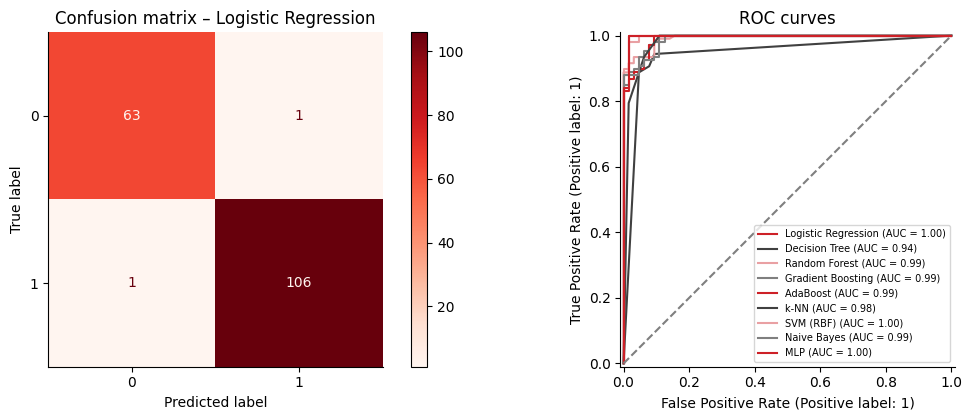

In [ ]:
#Metrics ( One Table with Every Model + the Main Plots )
rows = {}
if TASK == "classification":
    for n, p in pipes.items():
        pred, prob = p.predict(X_te), p.predict_proba(X_te)
        rows[n] = {"accuracy": accuracy_score(y_te, pred), "balanced acc.": balanced_accuracy_score(y_te, pred), "precision": precision_score(y_te, pred, average="macro", zero_division=0),
                   "recall": recall_score(y_te, pred, average="macro"), "F1": f1_score(y_te, pred, average="macro"), "ROC AUC": roc_auc_score(y_te, prob[:, 1] if len(CLASSES) == 2 else prob, multi_class="ovr"),
                   f"CV accuracy ({CV}-fold)": cross_val_score(p, X_tr, y_tr, cv=CV).mean()}
elif TASK == "regression":
    for n, p in pipes.items():
        pred = p.predict(X_te)
        rows[n] = {"MAE": mean_absolute_error(y_te, pred), "RMSE": mean_squared_error(y_te, pred) ** 0.5, "R²": r2_score(y_te, pred), "MAPE": mean_absolute_percentage_error(y_te, pred),
                   f"CV R² ({CV}-fold)": cross_val_score(p, X_tr, y_tr, cv=CV, scoring="r2").mean()}
else:
    for n, l in labels.items():
        ok, k = l != -1, len(set(l) - {-1})
        rows[n] = {"clusters": k, "noise %": 100 * (~ok).mean(), "silhouette": silhouette_score(Xs[ok], l[ok]) if k > 1 else np.nan,
                   "Calinski-Harabasz": calinski_harabasz_score(Xs[ok], l[ok]) if k > 1 else np.nan, "Davies-Bouldin": davies_bouldin_score(Xs[ok], l[ok]) if k > 1 else np.nan}
        if y is not None:
            rows[n].update({"ARI": adjusted_rand_score(y, l), "NMI": normalized_mutual_info_score(y, l)})
table = pd.DataFrame(rows).T
display(table.round(3))

best = {"classification": lambda: table["F1"].idxmax(), "regression": lambda: table["R²"].idxmax(), "clustering": lambda: table["silhouette"].idxmax()}[TASK]()
print("best model:", best)
if TASK == "classification":
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
    ConfusionMatrixDisplay.from_predictions(y_te, pipes[best].predict(X_te), display_labels=CLASSES, cmap="Reds", ax=ax[0]); ax[0].grid(False); ax[0].set_title(f"Confusion matrix – {best}")
    if len(CLASSES) == 2:
        for n, p in pipes.items():
            RocCurveDisplay.from_estimator(p, X_te, y_te, ax=ax[1], name=n)
        ax[1].plot([0, 1], [0, 1], "--", color="#7F7F7F"); ax[1].legend(fontsize=7, loc="lower right"); ax[1].set_title("ROC curves")
    else:
        ax[1].axis("off")
elif TASK == "regression":
    pred = pipes[best].predict(X_te)
    plt.figure(figsize=(5.5, 4.3)); plt.scatter(y_te, pred, s=18, color=RED); plt.plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], "--", color=DARK)
    plt.xlabel("actual"); plt.ylabel("predicted"); plt.title(f"Predicted × actual – {best}")
else:
    P = PCA(2).fit_transform(Xs)
    fig, ax = plt.subplots(1, len(labels), figsize=(3.4 * len(labels), 3.4))
    for a, (n, l) in zip(ax, labels.items()):
        a.scatter(P[:, 0], P[:, 1], c=l, cmap="tab10", s=10); a.set_title(n, fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### **4. Predict New Data (Optional)**

Uses the **best model**. The new data must have the **same columns** as the training features. Replace `X.head(3)` by `pd.get_dummies(pd.read_csv("new_data.csv")).reindex(columns=X.columns, fill_value=0)`.

In [ ]:
#Predict New Cases ( Classification and Regression )
new = X.head(3)
if TASK != "clustering":
    out = pipes[best].predict(new)
    print([CLASSES[i] for i in out] if TASK == "classification" else out.round(2))

['0', '0', '0']